# 01b · Station wind check

Does observed surface wind explain the disagreement between the measured dune motion and the MERRA-2 wind analysis?

Notebook 01 computed Fryberger drift potential from **MERRA-2** hourly 10 m wind (a ~0.5° × 0.625° reanalysis grid). At `seih_al_hama` notebook 02 then measured the dunes moving toward a field-median heading of about 29° (NNE), about 70° from the MERRA-2 resultant drift direction (RDD ≈ 100°). This notebook repeats the same Fryberger calculation with **observed winds from the nearest long-record weather stations** in NOAA's Integrated Surface Database (ISD / Global Hourly) and compares them with MERRA-2 at the station's own grid cell and at the site's cell, over the same period.

What this notebook does, in order:
1. **Find stations** within 60 km of the box centre (100 km if none qualifies) in NOAA's `isd-history.csv`, download their 2000-2024 station-years, and decide from the data which are usable (record length and reporting density). Station identifiers, coordinates and elevation are read from the source files; WMO OSCAR/Surface metadata is fetched as a cross-check.
2. **Decode and clean** the wind group: report types (METAR, SYNOP, SPECI, merged), calm and variable-direction codes, quality flags, whole-knot speeds, then build **one report per UTC hour** and show completeness by year, hour of day and month.
3. **Drift potential** with `dunesight.wind` (identical definitions to notebook 01): DP, RDP, RDD, RDP/DP, the 16-sector sand rose, the S and NW mode shares, % of hours above 12 kt, by month and by hour of day, for the station and for MERRA-2.
4. **Sensitivity** of DP and RDD to each data-handling choice.
5. **Secondary stations** (synoptic-hour comparison), a figure with the station and MERRA-2 sand roses side by side and the measured dune heading, and `pipeline/outputs/<site>/station_wind_check.json`.

MERRA-2 stays the project's primary wind source; nothing here is written to `public/data/`.

Run headless from `pipeline/`: `DUNESIGHT_SITE=seih_al_hama .venv/bin/jupyter nbconvert --to notebook --execute 01b_station_wind_check.ipynb --output-dir runs/seih_al_hama`.

In [1]:
# WHAT THIS DOES: finds the pipeline folder, imports the shared dunesight helpers, picks the site from
# DUNESIGHT_SITE, and sets the folders (station downloads go to pipeline/raw/stations/, gitignored).
import json, os, sys, time, datetime as dt
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

PIPELINE = next(p for p in [Path.cwd(), Path.cwd() / "pipeline", Path.cwd().parent, Path.cwd().parent.parent]
                if (p / "dunesight").is_dir())
sys.path.insert(0, str(PIPELINE))

import numpy as np
import pandas as pd
import requests
import matplotlib
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import Markdown, display

from dunesight import config, wind, merra2, stations as st

SITE = config.get_site()
SID = SITE["id"]
LAT_C, LON_C = config.centroid(SITE)
OUT = config.outputs_dir(SID); OUT.mkdir(parents=True, exist_ok=True)
RAW_ST = config.PIPELINE / "raw" / "stations"; RAW_ST.mkdir(parents=True, exist_ok=True)
GH = RAW_ST / "global_hourly"
META = RAW_ST / "meta"; META.mkdir(exist_ok=True)
REFRESH = os.environ.get("DUNESIGHT_REFRESH", "") == "1"
NOTES = PIPELINE / "site_notes" / SID
YEARS = list(range(2000, 2025))
load_dotenv(config.ROOT / ".env")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
print(f"site: {SID}  ({SITE['name']})  centre {LAT_C:.4f} N, {LON_C:.4f} E")
print("credentials present:", {k: bool(os.getenv(k)) for k in ("EE_PROJECT",)})

# The measured dune motion from notebook 02, if it has been run for this site.
_qc = OUT / "02_qc_summary.json"
DUNE = None
if _qc.exists():
    _p = json.loads(_qc.read_text()).get("physics", {})
    if "field_median_heading_deg" in _p:
        DUNE = {"field_median_heading_deg": _p["field_median_heading_deg"],
                "speed_weighted_mean_heading_deg": _p.get("speed_weighted_mean_heading_deg"),
                "heading_circular_sd_deg": _p.get("heading_circular_sd_deg"),
                "merra2_RDD_deg_used_in_02": _p.get("wind_RDD_deg")}
print("dune heading from notebook 02:", DUNE)

site: sweihan  (Sweihan dune field, NW of Al Ain)  centre 24.4650 N, 55.3400 E
credentials present: {'EE_PROJECT': True}
dune heading from notebook 02: None


## 1 · Which stations?

The search uses NOAA's station history file. A station counts as **usable** if it has at least 10 years in 2000-2024 with at least 2000 distinct hours carrying a valid wind report (about 5.5 a day: a synoptic station reporting every 3 hours qualifies, a station with a few scattered reports does not). The **primary** station is the nearest usable station that reports hourly (at least 7000 valid hours in at least 10 years); other usable stations are kept as **secondary** checks, compared at the synoptic hours (00, 03, ..., 21 UTC) they all share.

In [2]:
# WHAT THIS DOES: loads NOAA's isd-history.csv (downloaded once), lists every station within 150 km of the box centre
# with its distance, bearing and the period ISD says it covers, and picks the candidates to test (within 60 km, or
# 100 km if nothing within 60 km turns out usable) that overlap 2000-2024 by at least 3 years.
hist = st.load_isd_history(META / "isd-history.csv", refresh=REFRESH)
near = st.stations_near(hist, LAT_C, LON_C, max_km=150).copy()
near["bearing_from_site_deg"] = [st.bearing_deg(LAT_C, LON_C, a, b) for a, b in zip(near.lat, near.lon)]
near["overlap_years"] = [max(0, min(e.year, 2024) - max(b.year, 2000) + 1) for b, e in zip(near.begin, near.end)]
print(near[["id", "STATION NAME", "CTRY", "ICAO", "lat", "lon", "elev_m", "BEGIN", "END", "distance_km",
            "bearing_from_site_deg", "overlap_years"]].round(1).to_string(index=False))

def candidates(radius):
    return near[(near.distance_km <= radius) & (near.overlap_years >= 3)]

         id                STATION NAME CTRY ICAO  lat  lon  elev_m    BEGIN      END  distance_km  bearing_from_site_deg  overlap_years
41218099999                 AL AIN INTL   AE OMAL 24.3 55.6   264.9 19940308 20250824         35.4                  129.6             25
41194599999     AL MAKTOUM INTL AIRPORT   AE  NaN 24.9 55.2    18.9 20100518 20250824         49.8                  340.1             15
41244099999               BURAIMI (AUT)   MU OOBR 24.2 55.8   299.0 19830101 20250824         51.8                  119.8             25
40460099999                     BURAIMI   MU OOBR 24.2 55.8   295.0 19490104 20020921         55.4                  115.5              3
40469099999                     BURAIMI   MU OOFD 24.2 55.8   295.0 19780601 20011121         55.4                  115.5              2
41216499999             DUBAI MINHAD AB   AE OMDM 25.0 55.4    50.3 20080721 20201006         62.5                    2.4             13
41217099999 ABU DHABI INTL / ZAYED INTL  

In [3]:
# WHAT THIS DOES: downloads the 2000-2024 station-year files of each candidate (NOAA Open Data bucket, cached in
# pipeline/raw/stations/), decodes the wind group and counts, per year, the distinct UTC hours with a valid wind
# report; then applies the usability rule and chooses the primary and secondary stations.
def station_years(row):
    ys = [y for y in YEARS if row.begin.year <= y <= row.end.year]
    with ThreadPoolExecutor(6) as ex:
        list(ex.map(lambda y: st.download_year(row.id, y, GH, REFRESH), ys))
    raw = st.read_years(row.id, ys, GH)
    return st.decode_wind(raw) if len(raw) else None

DEC = {}
def screen(radius):
    rows = []
    for _, r in candidates(radius).iterrows():
        if r.id not in DEC:
            DEC[r.id] = station_years(r)
        d = DEC[r.id]
        per_year = pd.Series(dtype=float) if d is None else st.hourly(d, window_min=30, include_speci=True).groupby(lambda t: t.year).size()
        rows.append({"id": r.id, "name": r["STATION NAME"], "distance_km": round(r.distance_km, 1),
                     "years_ge_2000h": int((per_year >= 2000).sum()), "years_ge_7000h": int((per_year >= 7000).sum()),
                     "first": int(per_year.index.min()) if len(per_year) else None,
                     "last": int(per_year.index.max()) if len(per_year) else None,
                     "median_hours_per_year": float(per_year.median()) if len(per_year) else 0.0})
    return pd.DataFrame(rows)

SCREEN_RADIUS = 60
scr = screen(SCREEN_RADIUS)
if scr.empty or not (scr.years_ge_2000h >= 10).any():
    SCREEN_RADIUS = 100
    scr = screen(SCREEN_RADIUS)
scr["usable"] = scr.years_ge_2000h >= 10 if len(scr) else []
scr["hourly"] = scr.years_ge_7000h >= 10 if len(scr) else []
print(f"candidates within {SCREEN_RADIUS} km with >= 3 years overlapping 2000-2024:")
print(scr.to_string(index=False) if len(scr) else "  none")
_hourly = scr[scr.usable & scr.hourly].sort_values("distance_km") if len(scr) else scr
PRIMARY = _hourly.id.iloc[0] if len(_hourly) else None
SECONDARY = [s for s in scr[scr.usable].sort_values("distance_km").id if s != PRIMARY] if len(scr) else []
HAS_STATION = PRIMARY is not None
print("\nprimary station:", PRIMARY, "| secondary:", SECONDARY)
if not HAS_STATION:
    print(f"NO USABLE STATION for {SID}: the remaining cells only write station_wind_check.json saying so.")

candidates within 60 km with >= 3 years overlapping 2000-2024:
         id                    name  distance_km  years_ge_2000h  years_ge_7000h  first  last  median_hours_per_year  usable  hourly
41218099999             AL AIN INTL         35.4              25              25   2000  2024                 8650.0    True    True
41194599999 AL MAKTOUM INTL AIRPORT         49.8              15              14   2010  2024                 8699.0    True    True
41244099999           BURAIMI (AUT)         51.8              24               0   2000  2025                 2760.5    True   False
40460099999                 BURAIMI         55.4               0               0   2002  2002                    2.0   False   False

primary station: 41218099999 | secondary: ['41194599999', '41244099999']


In [4]:
# WHAT THIS DOES: reads each chosen station's identity from the downloaded files themselves (name, call sign,
# latitude, longitude, elevation as ISD stores them, and whether they change over the record), and fetches the WMO
# OSCAR/Surface record (WIGOS id 0-20000-0-<WMO number>) as an independent check of position and elevation.
# Neither ISD nor OSCAR gives the anemometer height or averaging time for these stations; that is reported as such.
def oscar(wmo):
    f = META / f"oscar_{wmo}.json"
    if f.exists() and not REFRESH:
        return json.loads(f.read_text())
    try:
        s = requests.get(f"https://oscar.wmo.int/surface/rest/api/search/station?wigosId=0-20000-0-{wmo}", timeout=60).json()
        if not s.get("stationSearchResults"):
            return None
        hit = s["stationSearchResults"][0]
        rep = requests.get(f"https://oscar.wmo.int/surface/rest/api/stations/station/{hit['id']}/stationReport", timeout=60).json()
        out = {"search": hit, "report_locations": rep.get("locations"), "report_observations": rep.get("observations")}
        f.write_text(json.dumps(out))
        return out
    except Exception as e:  # OSCAR is a cross-check only
        print("OSCAR lookup failed:", type(e).__name__)
        return None

STN = {}
for sid in ([PRIMARY] if HAS_STATION else []) + SECONDARY:
    d = DEC[sid]
    ident = d[["NAME", "CALL_SIGN", "LATITUDE", "LONGITUDE", "ELEVATION"]].drop_duplicates()
    lat, lon, elev = (float(ident.LATITUDE.iloc[0]), float(ident.LONGITUDE.iloc[0]), float(ident.ELEVATION.iloc[0]))
    # ISD USAF ids of WMO stations are the 5-digit WMO number followed by 0; other USAF ids (e.g. 411945) are
    # NCEI-assigned and must not be looked up as WMO numbers.
    wmo = sid[:5] if sid[5] == "0" else None
    o = oscar(wmo) if wmo else None
    oinfo = None
    if o:
        s = o["search"]
        oinfo = {"name": s["name"], "lat": s["latitude"], "lon": s["longitude"], "elevation_m": s["elevation"],
                 "date_established": s.get("dateEstablished"), "status": s.get("declaredStatus"),
                 "distance_from_isd_position_km": round(float(st.haversine_km(lat, lon, s["latitude"], s["longitude"])), 2),
                 "anemometer_metadata_in_oscar": bool(o.get("report_observations"))}
    STN[sid] = {"id": sid, "usaf": sid[:6], "wban": sid[6:], "wmo": wmo,
                "name": ident.NAME.iloc[0], "icao": next((c.strip() for c in ident.CALL_SIGN if c.strip() != "99999"), None),
                "lat": lat, "lon": lon, "elevation_m": elev, "isd_positions_in_record": int(len(ident[["LATITUDE", "LONGITUDE", "ELEVATION"]].drop_duplicates())),
                "distance_to_site_km": round(float(st.haversine_km(LAT_C, LON_C, lat, lon)), 1),
                "bearing_from_site_deg": round(st.bearing_deg(LAT_C, LON_C, lat, lon), 0),
                "oscar": oinfo,
                "source_urls": [st.NCEI_ACCESS_URL.format(year="<year>", sid=sid), st.S3_URL.format(year="<year>", sid=sid)]
                               + ([f"https://oscar.wmo.int/surface/#/search/station/stationReportDetails/0-20000-0-{wmo}"] if wmo else [])}
    if oinfo and oinfo["distance_from_isd_position_km"] > 2:
        STN[sid]["distance_to_site_km_oscar_position"] = round(float(st.haversine_km(LAT_C, LON_C, oinfo["lat"], oinfo["lon"])), 1)
for k, v in STN.items():
    print(json.dumps(v, indent=1, default=str))

{
 "id": "41218099999",
 "usaf": "412180",
 "wban": "99999",
 "wmo": "41218",
 "name": "AL AIN INTERNATIONAL, AE",
 "icao": "OMAL",
 "lat": 24.261667,
 "lon": 55.609167,
 "elevation_m": 264.87,
 "isd_positions_in_record": 1,
 "distance_to_site_km": 35.4,
 "bearing_from_site_deg": 130.0,
 "oscar": {
  "name": "AL AIN INTERNATIONAL AIRPORT",
  "lat": 24.2666666667,
  "lon": 55.6,
  "elevation_m": 265,
  "date_established": null,
  "status": "Operational",
  "distance_from_isd_position_km": 1.08,
  "anemometer_metadata_in_oscar": false
 },
 "source_urls": [
  "https://www.ncei.noaa.gov/data/global-hourly/access/<year>/41218099999.csv",
  "https://noaa-global-hourly-pds.s3.amazonaws.com/<year>/41218099999.csv",
  "https://oscar.wmo.int/surface/#/search/station/stationReportDetails/0-20000-0-41218"
 ]
}
{
 "id": "41194599999",
 "usaf": "411945",
 "wban": "99999",
 "wmo": null,
 "name": "AL MAKTOUM INTERNATIONAL AIRPORT, AE",
 "icao": "OMDW",
 "lat": 24.88611,
 "lon": 55.17222,
 "elevation_m

## 2 · Decoding and one report per hour

Rules (the sensitivity table in section 4 shows what each one changes):
- **Report types.** METAR (`FM-15`) is the routine hourly report; `SY-MT` is ISD's merge of a SYNOP and a METAR at the same time; `FM-12` is SYNOP. **SPECI** (`FM-16`) reports are excluded by default: they are issued when conditions change (often the wind), so they over-sample changing, often windy, conditions.
- **One report per UTC hour**: the valid report nearest the top of the hour within ±10 minutes, preferring METAR, then SY-MT, then SYNOP. Each observed hour then has equal weight, and `wind.fryberger` uses t = 100 / N with N = the hours actually observed in that year.
- **Calms** (type `C` or speed 0) are valid hours with zero drift; dropping them would inflate DP.
- **Variable direction** (type `V`): if a mean direction is given it is used; if not (direction 999) the hour is valid, and at or below 12 kt it adds nothing to DP whatever its direction. Hours with no direction **above** 12 kt cannot be placed in the rose and are dropped (counted below).
- **Quality codes** 2, 3, 6, 7 (suspect / erroneous) on speed, or on direction of a non-calm wind, are rejected.
- **Speed units**: these stations report whole knots; ISD stores m/s to 0.1, so the reported knot value is recovered with round(m/s ÷ 0.514444).
- **Direction resolution**: directions are reported to 10°. For the 16-sector rose each report is spread evenly over its 10° bin (`stations.split_directions`), because otherwise some 22.5° sectors receive three 10° values and others two.

In [5]:
# WHAT THIS DOES: for each chosen station prints the report types by year, the wind type codes, quality-code
# rejections, calms, variable winds with and without a direction (and how many of those exceed 12 kt), and checks
# that the stored speeds are whole knots.
REPORTS = {}
for sid in STN:
    d = DEC[sid]
    print(f"===== {sid} {STN[sid]['name']}: {len(d)} reports, {int(d.valid.sum())} with a usable wind")
    print(pd.crosstab(d.time.dt.year, d.REPORT_TYPE).to_string())
    print("wind type codes by report type:\n", pd.crosstab(d.REPORT_TYPE, d.type_code).to_string())
    knots_whole = float(np.mean(np.abs(d.kt_raw[d.spd_ms.notna()] - np.round(d.kt_raw[d.spd_ms.notna()])) < 0.11))
    rep = {"reports": int(len(d)), "valid_reports": int(d.valid.sum()), "qc_rejected": int(d.qc_bad.sum()),
           "missing_speed": int(d.spd_ms.isna().sum()), "calm_reports": int(d.calm.sum()),
           "variable_with_direction": int(((d.type_code == "V") & d.dir_deg.notna()).sum()),
           "variable_no_direction": int(d.vrb_nodir.sum()),
           "variable_no_direction_above_12kt": int((d.vrb_nodir & (d.kt > 12)).sum()),
           "share_speeds_whole_knots": round(knots_whole, 4),
           "report_types": d.REPORT_TYPE.value_counts().to_dict()}
    REPORTS[sid] = rep
    print(json.dumps(rep, indent=1))

===== 41218099999 AL AIN INTERNATIONAL, AE: 245840 reports, 244779 with a usable wind
REPORT_TYPE  99999  FM-12  FM-15  FM-16  SAO  SY-MT
time                                               
2000             0     16   8132    258    6    153
2001             0      1   8508    170    9     22
2002             4      2   8484    282    1     21
2003             0      0   8388    150    0      5
2004             0     46   7079     13    0   1400
2005             0    124   6414      9    0   1970
2006             0    158   5653      0    0   2598
2007             0     75   6384      0    0   1939
2008             0     46   5902      0    0   2718
2009             0     17   5967      1    0   2702
2010             0     59   5893    160    0   2721
2011             0     47   6022    230    0   2628
2012             0      7   5868    210    0   2881
2013             0   1463   7757    254    0    908
2014             0   2721   8643    178    0      0
2015             0   2225   87

In [6]:
# WHAT THIS DOES: builds the hourly series (one report per UTC hour) for each chosen station, drops direction-less
# hours above 12 kt, converts to U, V in m/s, and prints completeness by year; for the primary station it also
# shows completeness by year x hour of day and by month, so a gap pattern cannot pass for a diurnal or seasonal signal.
def station_hourly(sid, **kw):
    h = st.hourly(DEC[sid], **kw)
    h = h[(h.index.year >= YEARS[0]) & (h.index.year <= YEARS[-1])]
    h = h[~(h.vrb_nodir & (h.kt > wind.VT_KT))]
    u, v = st.to_uv(h.kt.values, h.dir_deg.values)
    return h.assign(u=u, v=v)

HOURLY = {sid: station_hourly(sid) for sid in STN}
COMPLETENESS = {}
for sid, h in HOURLY.items():
    n = h.groupby(h.index.year).size().reindex(YEARS, fill_value=0)
    exp = pd.Series([wind.hours_in_year(y) for y in YEARS], index=YEARS)
    COMPLETENESS[sid] = (100 * n / exp).round(1)
    print(f"{sid}: % of hours with a report, by year:\n{COMPLETENESS[sid].to_string()}")
if HAS_STATION:
    h = HOURLY[PRIMARY]
    yh = h.groupby([h.index.year, h.index.hour]).size().unstack(fill_value=0)
    days = pd.Series([wind.hours_in_year(y) / 24 for y in yh.index], index=yh.index)
    yh_pct = (100 * yh.div(days, axis=0)).round(0)
    print(f"\n{PRIMARY}: % of days with a report at each UTC hour (rows = year):")
    print(yh_pct.astype(int).to_string())
    print("\nall years, % by hour of day:", (100 * h.groupby(h.index.hour).size() / (len(pd.date_range(f'{YEARS[0]}-01-01', f'{YEARS[-1]}-12-31', freq='D')))).round(1).to_dict())
    mcount = h.groupby(h.index.month).size()
    mexp = pd.date_range(f"{YEARS[0]}-01-01", f"{YEARS[-1]}-12-31 23:00", freq="h").month.value_counts().sort_index()
    print("all years, % by month:", (100 * mcount / mexp).round(1).to_dict())
    print(f"hour-of-day completeness spread (max - min): {float(yh_pct.mean().max() - yh_pct.mean().min()):.1f} percentage points")

41218099999: % of hours with a report, by year:
hour
2000    89.1
2001    94.6
2002    96.3
2003    95.6
2004    96.9
2005    97.0
2006    95.7
2007    95.7
2008    98.4
2009    99.1
2010    98.5
2011    99.1
2012    99.7
2013    99.1
2014    98.9
2015    99.8
2016    99.6
2017    99.8
2018    99.5
2019    99.6
2020    99.5
2021    96.5
2022    98.9
2023    98.7
2024    95.4
41194599999: % of hours with a report, by year:
hour
2000     0.0
2001     0.0
2002     0.0
2003     0.0
2004     0.0
2005     0.0
2006     0.0
2007     0.0
2008     0.0
2009     0.0
2010    51.7
2011    95.5
2012    99.3
2013    99.6
2014    99.3
2015    99.8
2016    99.5
2017    99.8
2018    99.1
2019    99.4
2020    99.3
2021    96.5
2022    98.8
2023    98.5
2024    95.2
41244099999: % of hours with a report, by year:
hour
2000    32.0
2001    31.4
2002    32.8
2003    32.2
2004    31.8
2005    30.8
2006    32.0
2007    32.1
2008    31.0
2009    29.7
2010    24.4
2011    27.5
2012    17.5
2013    32.0
2014    2

## 3 · MERRA-2 at the station's grid cell and at the site's cell

The MERRA-2 series are read exactly as in notebook 01: the native cell containing the point, sampled in Earth Engine by **native index** (Earth Engine's `NASA/GSFC/MERRA/slv/2` grid is offset by half a cell, see `dunesight/merra2.py`). Notebook 01 already cached the site cells; a cell not cached yet is fetched the same way. Earth Engine stamps each MERRA-2 hour with the start of its averaging hour (the mean over HH:00-HH+1:00, centred HH:30), while a METAR at HH:00 is a 10-minute mean ending at HH:00. For the hour-by-hour pairing below the station report at HH:00 is compared with the mean of the MERRA-2 hours labelled HH-1 and HH (centred on HH:00); the period statistics use all MERRA-2 hours, or only the hours the station observed.

In [7]:
# WHAT THIS DOES: finds the native MERRA-2 cell of the site and of each station, loads each cell's 2000-2024 hourly
# series from a notebook-01 cache under pipeline/raw/<any site>/ or, if missing, fetches it from Earth Engine by
# native index (one request per year) into pipeline/raw/stations/.
def merra_cell(lat, lon):
    c = merra2.native_cell(lat, lon)
    name = f"merra2_u10v10_hourly_i{c['i']}_j{c['j']}.csv"
    hits = sorted((config.PIPELINE / "raw").glob(f"*/{name}"))
    if hits and not REFRESH:
        m = pd.read_csv(hits[0], parse_dates=["time"]); src = hits[0].relative_to(config.ROOT)
    else:
        from dunesight import landsat
        ee = landsat.ee_init(config.ROOT)
        slv = ee.ImageCollection("NASA/GSFC/MERRA/slv/2")
        T = slv.first().select("U10M").projection().getInfo()["transform"]
        xy = merra2.ee_pixel_centre(T, c["i"], c["j"])
        def year(y):
            col = slv.filterDate(f"{y}-01-01", f"{y + 1}-01-01").select(["U10M", "V10M"])
            for attempt in range(5):
                try:
                    rows = col.getRegion(ee.Geometry.Point(list(xy)), scale=None, crs="EPSG:4326", crsTransform=T).getInfo()
                    df = pd.DataFrame(rows[1:], columns=rows[0])
                    df["time"] = pd.to_datetime(df["time"], unit="ms", utc=True)
                    return df[["time", "U10M", "V10M"]]
                except Exception:
                    if attempt == 4:
                        raise
                    time.sleep(5 * (attempt + 1))
        with ThreadPoolExecutor(6) as ex:
            m = pd.concat(list(ex.map(year, YEARS)), ignore_index=True)
        f = RAW_ST / name; m.to_csv(f, index=False); src = f.relative_to(config.ROOT)
    m["time"] = pd.to_datetime(m["time"], utc=True)
    m = m.drop_duplicates("time").set_index("time").sort_index()
    m = m[(m.index.year >= YEARS[0]) & (m.index.year <= YEARS[-1])].dropna()
    print(f"cell i={c['i']} j={c['j']} centre {c['lat_c']} N {c['lon_c']} E: {len(m)} hours from {src}")
    return c, m

SITE_CELL, M_SITE = merra_cell(LAT_C, LON_C)
CELLS = {}
for sid, s in STN.items():
    CELLS[sid] = merra_cell(s["lat"], s["lon"])
    c = CELLS[sid][0]
    s["merra2_cell"] = {"i": c["i"], "j": c["j"], "lat_c": c["lat_c"], "lon_c": c["lon_c"],
                        "same_as_site_cell": (c["i"], c["j"]) == (SITE_CELL["i"], SITE_CELL["j"]),
                        "station_to_cell_edge_km": round(float(min(abs(s["lat"] - c["south"]), abs(s["lat"] - c["north"])) * 111.0), 1)}
    print(f"  {sid}: station sits {s['merra2_cell']['station_to_cell_edge_km']} km (N-S) from its cell's nearest N/S edge; same cell as the site: {s['merra2_cell']['same_as_site_cell']}")

cell i=377 j=229 centre 24.5 N 55.625 E: 219168 hours from pipeline/raw/sweihan/merra2_u10v10_hourly_i377_j229.csv
cell i=377 j=229 centre 24.5 N 55.625 E: 219168 hours from pipeline/raw/sweihan/merra2_u10v10_hourly_i377_j229.csv
  41218099999: station sits 1.3 km (N-S) from its cell's nearest N/S edge; same cell as the site: True
cell i=376 j=230 centre 25.0 N 55.0 E: 219168 hours from pipeline/raw/stations/merra2_u10v10_hourly_i376_j230.csv
  41194599999: station sits 15.1 km (N-S) from its cell's nearest N/S edge; same cell as the site: False
cell i=377 j=228 centre 24.0 N 55.625 E: 219168 hours from pipeline/raw/seih_al_hama/merra2_u10v10_hourly_i377_j228.csv
  41244099999: station sits 1.9 km (N-S) from its cell's nearest N/S edge; same cell as the site: False


## 4 · Station versus MERRA-2

In [8]:
# WHAT THIS DOES: computes the Fryberger summary (mean annual DP, RDP, RDD, RDP/DP, class, % hours > 12 kt, speeds,
# S and NW mode shares) for the primary station and for MERRA-2 at (a) the station's cell, all hours; (b) the
# station's cell, only the hours the station observed; (c) the site's cell (the notebook-01 value), over 2000-2024
# and over 2013-2024 (the Landsat 8/9 tracking period).
def summ_station(h):
    kt_s, d_s = st.split_directions(h.kt.values, h.dir_deg.values)
    t_s = np.repeat(h.index.values, 10)
    u_s, v_s = st.to_uv(kt_s, d_s)
    base = st.summarize(h.index, h.u.values, h.v.values)          # DP, RDP, RDD from the reports as given
    split = st.summarize(pd.DatetimeIndex(t_s, tz="UTC"), u_s, v_s)  # rose and mode shares with 10-degree bins spread
    for k in ("rose_from", *st.mode_shares(split["rose_from"]).keys()):
        base[k] = split[k]
    base["rose_from_unsplit"] = st.summarize(h.index, h.u.values, h.v.values)["rose_from"]
    return base

def summ_merra(m):
    return st.summarize(m.index, m.U10M.values, m.V10M.values)

ROW_KEYS = ["DP", "RDP", "RDD_deg", "RDP_DP", "dp_class", "pct_hours_above_vt", "mean_kt", "p90_kt", "p99_kt",
            "S (157.5-202.5)", "NW (292.5-315)", "S_over_NW", "n_hours", "n_years"]
COMPARE, SUMS = [], {}
if HAS_STATION:
    H = HOURLY[PRIMARY]; MC = CELLS[PRIMARY][1]; cc = CELLS[PRIMARY][0]
    for period, (y0, y1) in {"2000-2024": (2000, 2024), "2013-2024": (2013, 2024)}.items():
        hs = H[(H.index.year >= y0) & (H.index.year <= y1)]
        ms = MC[(MC.index.year >= y0) & (MC.index.year <= y1)]
        mss = M_SITE[(M_SITE.index.year >= y0) & (M_SITE.index.year <= y1)]
        cases = {f"station {PRIMARY} ({STN[PRIMARY]['icao'] or STN[PRIMARY]['name']})": summ_station(hs),
                 f"MERRA-2 station cell i{cc['i']} j{cc['j']}, all hours": summ_merra(ms),
                 f"MERRA-2 station cell i{cc['i']} j{cc['j']}, station-observed hours": summ_merra(ms[ms.index.isin(hs.index)]),
                 f"MERRA-2 site cell i{SITE_CELL['i']} j{SITE_CELL['j']}, all hours": summ_merra(mss)}
        for label, s in cases.items():
            SUMS[(period, label)] = s
            COMPARE.append({"period": period, "series": label, **{k: s[k] for k in ROW_KEYS}})
    COMPARE = pd.DataFrame(COMPARE)
    print(COMPARE.round(3).to_string(index=False))
    COMPARE.round(4).to_csv(OUT / "station_wind_compare.csv", index=False)
    k_st = ("2000-2024", COMPARE.series.iloc[0]); k_mc = ("2000-2024", COMPARE.series.iloc[1]); k_ms = ("2000-2024", COMPARE.series.iloc[3])
    print(f"\nDP ratio station / MERRA-2 station cell: {SUMS[k_st]['DP'] / SUMS[k_mc]['DP']:.2f}; "
          f"station / MERRA-2 site cell: {SUMS[k_st]['DP'] / SUMS[k_ms]['DP']:.2f}")
    print(f"RDD: station {SUMS[k_st]['RDD_deg']:.1f} deg, MERRA-2 station cell {SUMS[k_mc]['RDD_deg']:.1f}, site cell {SUMS[k_ms]['RDD_deg']:.1f}")
    if DUNE:
        dh = DUNE["field_median_heading_deg"]
        print(f"angle to the measured dune heading ({dh:.1f} deg): station {float(wind.angle_diff(SUMS[k_st]['RDD_deg'], dh)):.1f}, "
              f"MERRA-2 station cell {float(wind.angle_diff(SUMS[k_mc]['RDD_deg'], dh)):.1f}, site cell {float(wind.angle_diff(SUMS[k_ms]['RDD_deg'], dh)):.1f} deg")

   period                                                 series      DP    RDP  RDD_deg  RDP_DP dp_class  pct_hours_above_vt  mean_kt  p90_kt  p99_kt  S (157.5-202.5)  NW (292.5-315)  S_over_NW  n_hours  n_years
2000-2024                             station 41218099999 (OMAL) 131.966 35.790    8.731   0.271      low              12.677    7.617  13.000  19.000            0.550           0.221      2.490   214010       25
2000-2024              MERRA-2 station cell i377 j229, all hours  70.216 30.310   87.191   0.432      low               9.854    6.764  11.958  17.553            0.267           0.515      0.519   219168       25
2000-2024 MERRA-2 station cell i377 j229, station-observed hours  70.368 30.195   87.349   0.429      low               9.891    6.768  11.967  17.558            0.266           0.515      0.517   214010       25
2000-2024                 MERRA-2 site cell i377 j229, all hours  70.216 30.310   87.191   0.432      low               9.854    6.764  11.958  17.5

In [9]:
# WHAT THIS DOES: tabulates the 16-sector sand rose (mean annual DP by FROM sector, and % of DP) for the station
# (10-degree bins spread, and as reported) and for MERRA-2 at the station and site cells, 2000-2024.
if HAS_STATION:
    s_st, s_mc, s_ms = SUMS[k_st], SUMS[k_mc], SUMS[k_ms]
    ROSE = pd.DataFrame({"sector_from_deg": np.arange(16) * 22.5,
                         "station_dp": s_st["rose_from"], "station_dp_unsplit": s_st["rose_from_unsplit"],
                         "merra2_station_cell_dp": s_mc["rose_from"], "merra2_site_cell_dp": s_ms["rose_from"]})
    for c in ["station_dp", "merra2_station_cell_dp", "merra2_site_cell_dp"]:
        ROSE[c.replace("_dp", "_pct")] = 100 * ROSE[c] / ROSE[c].sum()
    ROSE["sand_moves_to_deg"] = (ROSE.sector_from_deg + 180) % 360
    print(ROSE.round(2).to_string(index=False))
    ROSE.round(3).to_csv(OUT / "station_sand_rose.csv", index=False)

 sector_from_deg  station_dp  station_dp_unsplit  merra2_station_cell_dp  merra2_site_cell_dp  station_pct  merra2_station_cell_pct  merra2_site_cell_pct  sand_moves_to_deg
             0.0        3.64                4.94                    0.16                 0.16         2.76                     0.22                  0.22              180.0
            22.5        2.14                1.68                    0.06                 0.06         1.62                     0.09                  0.09              202.5
            45.0        1.16                1.03                    0.19                 0.19         0.88                     0.28                  0.28              225.0
            67.5        1.17                0.88                    1.58                 1.58         0.89                     2.24                  2.24              247.5
            90.0        2.74                3.64                    4.28                 4.28         2.08                     6.10    

In [10]:
# WHAT THIS DOES: breaks DP down by calendar month and by hour of day (UTC; local = UTC+4) for the station and for
# MERRA-2 at the station's cell (station-observed hours), each row = that group's contribution to the mean annual DP
# with the group's RDD, RDP/DP, % of hours above 12 kt and mean speed. The station's completeness per hour is shown
# next to it. MERRA-2 hour HH is the mean over HH:00-HH+1:00, i.e. centred half an hour after the station's HH:00.
if HAS_STATION:
    hs = H; ms = MC[MC.index.isin(H.index)]
    BY_MONTH = pd.concat({"station": st.group_contrib(hs.index, hs.u, hs.v, hs.index.month),
                          "merra2": st.group_contrib(ms.index, ms.U10M, ms.V10M, ms.index.month)}, axis=1)
    BY_HOUR = pd.concat({"station": st.group_contrib(hs.index, hs.u, hs.v, hs.index.hour),
                         "merra2": st.group_contrib(ms.index, ms.U10M, ms.V10M, ms.index.hour)}, axis=1)
    BY_HOUR[("station", "pct_days_reported")] = (100 * hs.groupby(hs.index.hour).size() / (len(hs.index.normalize().unique()))).round(1)
    BY_MONTH.index.name = "month"; BY_HOUR.index.name = "hour_utc"
    cols = ["DP_contrib", "RDD_deg", "RDP_DP", "pct_hours_above_12kt", "mean_kt"]
    print("by month:"); print(BY_MONTH.loc[:, (slice(None), cols)].round(2).to_string())
    print("\nby hour of day (UTC):"); print(BY_HOUR.loc[:, (slice(None), cols + ["pct_days_reported"])].round(2).to_string())
    flat = lambda t: t.set_axis([f"{a}_{b}" for a, b in t.columns], axis=1)
    flat(BY_MONTH).round(3).to_csv(OUT / "station_wind_by_month.csv")
    flat(BY_HOUR).round(3).to_csv(OUT / "station_wind_by_hour.csv")
    # where in the day each mode blows (share of that mode's DP by hour), station vs MERRA-2
    def mode_by_hour(t, u, v):
        q = wind.weighting(wind.speed_kt(u, v)); sec = wind.sector_index(wind.from_dir_deg(u, v))
        out = {}
        for name, secs in st.MODE_SECTORS.items():
            m = np.isin(sec, secs)
            out[name] = pd.Series(q * m, index=t).groupby(t.hour).sum() / (q * m).sum() * 100
        return pd.DataFrame(out)
    kt_s, d_s = st.split_directions(hs.kt.values, hs.dir_deg.values); u_s, v_s = st.to_uv(kt_s, d_s)
    MODE_HOUR = pd.concat({"station": mode_by_hour(pd.DatetimeIndex(np.repeat(hs.index.values, 10), tz="UTC"), u_s, v_s),
                           "merra2": mode_by_hour(ms.index, ms.U10M.values, ms.V10M.values)}, axis=1)
    print("\nshare of each mode's DP by hour of day (UTC), %:"); print(MODE_HOUR.round(1).to_string())

by month:
         station                                                 merra2                                            
      DP_contrib RDD_deg RDP_DP pct_hours_above_12kt mean_kt DP_contrib RDD_deg RDP_DP pct_hours_above_12kt mean_kt
month                                                                                                              
1           7.16  355.41   0.58                 7.83    6.86       5.68   73.98   0.49                 8.76    6.64
2          14.92  352.89   0.66                12.87    7.72       9.87   60.53   0.53                12.26    7.20
3          23.51  350.37   0.60                17.11    8.26      11.56   49.10   0.47                15.09    7.50
4          15.45   41.62   0.19                15.89    8.10       8.16   92.13   0.58                14.27    7.20
5          15.96  109.66   0.36                17.70    8.03      10.60  112.81   0.82                15.37    7.23
6          13.11  119.42   0.37                16.07    7.85  


share of each mode's DP by hour of day (UTC), %:
           station                         merra2               
   S (157.5-202.5) NW (292.5-315) S (157.5-202.5) NW (292.5-315)
0              4.7            0.1             2.0            0.1
1              4.5            0.1             2.4            0.1
2              4.6            0.2             4.1            0.1
3              4.9            0.2             9.2            0.2
4              7.6            0.0            14.2            1.6
5             11.4            0.2            15.3            3.7
6             13.2            0.7            13.7            5.7
7             11.2            1.8            10.9            7.9
8              7.8            4.2             8.0           10.6
9              5.8            6.6             6.0           13.6
10             4.0            9.1             4.0           15.8
11             3.1           13.1             2.6           16.5
12             2.5           16.0       

In [11]:
# WHAT THIS DOES: pairs every station hour with MERRA-2 at the station's cell (mean of the two MERRA-2 hours
# straddling the report time) and compares speeds (bias, quantiles, % above 12 kt), and, for hours when the
# station is above 12 kt, which direction MERRA-2 gives. It also shows the strong southerly station hours: what
# MERRA-2 says at the same time.
if HAS_STATION:
    s_st, s_mc, s_ms = SUMS[k_st], SUMS[k_mc], SUMS[k_ms]
    mm = MC[["U10M", "V10M"]]
    mid = (mm + mm.shift(1, freq="h")) / 2      # label HH: mean of the hours labelled HH-1 and HH, centred on HH:00
    P = H[["kt", "dir_deg", "u", "v"]].join(mid, how="inner").dropna(subset=["U10M"])
    P["m_kt"] = wind.speed_kt(P.U10M, P.V10M); P["m_from"] = wind.from_dir_deg(P.U10M, P.V10M)
    qs = [0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
    PAIRED = {"n_pairs": int(len(P)), "mean_kt_station": float(P.kt.mean()), "mean_kt_merra2": float(P.m_kt.mean()),
              "corr_speed": float(np.corrcoef(P.kt, P.m_kt)[0, 1]),
              "corr_u": float(np.corrcoef(P.u, P.U10M)[0, 1]), "corr_v": float(np.corrcoef(P.v, P.V10M)[0, 1]),
              "quantiles_kt_station": dict(zip(map(str, qs), np.quantile(P.kt, qs).round(2).tolist())),
              "quantiles_kt_merra2": dict(zip(map(str, qs), np.quantile(P.m_kt, qs).round(2).tolist())),
              "pct_above_12kt_station": float((P.kt > 12).mean() * 100), "pct_above_12kt_merra2": float((P.m_kt > 12).mean() * 100)}
    strong = P[P.kt > 12]
    sec_st = wind.sector_index(strong.dir_deg.fillna(0)); sec_m = wind.sector_index(strong.m_from)
    PAIRED["strong_station_hours"] = int(len(strong))
    PAIRED["strong_hours_median_abs_dir_diff_deg"] = float(np.median(wind.angle_diff(strong.dir_deg, strong.m_from)))
    s_hours = strong[np.isin(sec_st, st.MODE_SECTORS["S (157.5-202.5)"])]
    PAIRED["station_strong_S_hours"] = int(len(s_hours))
    PAIRED["merra2_at_those_hours_median_kt"] = float(s_hours.m_kt.median())
    PAIRED["merra2_at_those_hours_pct_above_12kt"] = float((s_hours.m_kt > 12).mean() * 100)
    PAIRED["merra2_at_those_hours_pct_also_S_sector"] = float(np.isin(wind.sector_index(s_hours.m_from), st.MODE_SECTORS["S (157.5-202.5)"]).mean() * 100)
    PAIRED["merra2_at_those_hours_median_from_deg"] = float(np.degrees(np.angle(np.mean(np.exp(1j * np.radians(s_hours.m_from))))) % 360)
    # per mode: how strong is each mode in MERRA-2 relative to the station? (DP from the rose sectors; mean speed over
    # the hours when BOTH series blow from the mode's sectors)
    sec_all_st = wind.sector_index(P.dir_deg.fillna(-999)); sec_all_m = wind.sector_index(P.m_from)
    PAIRED["by_mode"] = {}
    for name, secs in st.MODE_SECTORS.items():
        both = np.isin(sec_all_st, secs) & np.isin(sec_all_m, secs) & P.dir_deg.notna().values
        PAIRED["by_mode"][name] = {
            "DP_station_vu": float(s_st["rose_from"][secs].sum()), "DP_merra2_station_cell_vu": float(s_mc["rose_from"][secs].sum()),
            "DP_ratio_station_over_merra2": float(s_st["rose_from"][secs].sum() / s_mc["rose_from"][secs].sum()),
            "hours_both_from_mode": int(both.sum()),
            "mean_kt_station_when_both": float(P.kt[both].mean()), "mean_kt_merra2_when_both": float(P.m_kt[both].mean()),
            "speed_ratio_station_over_merra2_when_both": float(P.kt[both].mean() / P.m_kt[both].mean())}
    print(json.dumps(PAIRED, indent=1))
    # speed distribution, binned
    bins = np.arange(0, 41, 2)
    dist = pd.DataFrame({"station_pct": np.histogram(P.kt, bins)[0] / len(P) * 100,
                         "merra2_pct": np.histogram(P.m_kt, bins)[0] / len(P) * 100}, index=[f"{a}-{a + 2}" for a in bins[:-1]])
    print("\nspeed distribution, % of paired hours by 2-kt bin:"); print(dist.round(3).to_string())
    # 2-D table: station FROM sector of strong hours vs MERRA-2 FROM sector
    ct = pd.crosstab(pd.Series(sec_st * 22.5, name="station_from"), pd.Series(sec_m * 22.5, name="merra2_from"))
    print("\nhours with station > 12 kt: station FROM sector (rows) vs MERRA-2 FROM sector (columns):"); print(ct.to_string())

{
 "n_pairs": 214009,
 "mean_kt_station": 7.617445995261882,
 "mean_kt_merra2": 6.731289461610417,
 "corr_speed": 0.5596330248822426,
 "corr_u": 0.6779595224868695,
 "corr_v": 0.7770513805316112,
 "quantiles_kt_station": {
  "0.5": 7.0,
  "0.75": 10.0,
  "0.9": 13.0,
  "0.95": 15.0,
  "0.99": 19.0,
  "0.999": 25.0
 },
 "quantiles_kt_merra2": {
  "0.5": 5.98,
  "0.75": 8.76,
  "0.9": 11.84,
  "0.95": 13.73,
  "0.99": 17.44,
  "0.999": 22.12
 },
 "pct_above_12kt_station": 12.688251428678232,
 "pct_above_12kt_merra2": 9.456611637828317,
 "strong_station_hours": 27154,
 "strong_hours_median_abs_dir_diff_deg": 16.90051876111238,
 "station_strong_S_hours": 13194,
 "merra2_at_those_hours_median_kt": 10.104998092396926,
 "merra2_at_those_hours_pct_above_12kt": 31.4006366530241,
 "merra2_at_those_hours_pct_also_S_sector": 68.0839775655601,
 "merra2_at_those_hours_median_from_deg": 175.92272824830252,
 "by_mode": {
  "S (157.5-202.5)": {
   "DP_station_vu": 72.52726139504995,
   "DP_merra2_stati

## 5 · How much does each data-handling choice move the answer?

Each row changes one choice relative to the baseline (one report per hour, METAR first, SPECI excluded, whole knots recovered, calms counted, t = 100 / N observed hours). DP depends on roughly the cube of speed above the threshold, so speed-related choices matter most. Two rows are not choices but **plausible biases** of an airport anemometer relative to MERRA-2's 10 m hourly mean: a ±5 % speed error (calibration, or an anemometer at about 7 m instead of 10 m over open desert with a roughness length of ~1 cm), and the 10-minute versus hourly averaging (approximated by a 1-2-1 vector average of each hour with its neighbours, which smooths more than an hourly mean would, so it is an upper bound on that effect).

In [12]:
# WHAT THIS DOES: recomputes DP, RDD and RDP/DP of the primary station for each alternative choice and reports the
# change from the baseline (DP in %, RDD in degrees).
def dp_case(h):
    s = st.summarize(h.index, h.u.values, h.v.values)
    return {k: s[k] for k in ("DP", "RDP", "RDD_deg", "RDP_DP", "pct_hours_above_vt", "n_hours")}

SENS = []
if HAS_STATION:
    rng = np.random.default_rng(20261114)
    d0 = DEC[PRIMARY]
    def from_dec(dec, **kw):
        h = st.hourly(dec, **kw); h = h[(h.index.year >= YEARS[0]) & (h.index.year <= YEARS[-1])]
        h = h[~(h.vrb_nodir & (h.kt > wind.VT_KT))]
        u, v = st.to_uv(h.kt.values, h.dir_deg.values); return h.assign(u=u, v=v)
    def with_kt(h, kt):
        u, v = st.to_uv(kt, h.dir_deg.values); return h.assign(kt=kt, u=u, v=v)
    base = HOURLY[PRIMARY]
    cases = {"baseline": base,
             "speeds as stored by ISD (no rounding to whole knots)": from_dec(st.decode_wind(d0.drop(columns=[c for c in d0.columns if c not in st.COLS]), round_to_knots=False)),
             "whole-knot speeds dithered +/-0.5 kt (quantisation)": with_kt(base, np.where(base.kt > 0, base.kt + rng.uniform(-0.5, 0.5, len(base)), 0.0)),
             "SPECI reports allowed (hour slot)": from_dec(d0, include_speci=True),
             "every valid report, any minute, SPECI included": None,
             "report window +/-30 min": from_dec(d0, window_min=30),
             "synoptic hours only (00, 03, ..., 21 UTC)": from_dec(d0, synoptic_only=True),
             "calms dropped (wrong; shows the effect)": base[base.kt > 0],
             "speed x 0.95": with_kt(base, base.kt.values * 0.95),
             "speed x 1.05": with_kt(base, base.kt.values * 1.05),
             "1-2-1 vector average over neighbouring hours (averaging-time proxy)": None,
             "MERRA-2 threshold equivalence: station speed x (MERRA-2 / station mean speed)": None}
    # every report (not one per hour): each report gets equal weight
    allr = d0[d0.valid & ~(d0.vrb_nodir & (d0.kt > wind.VT_KT))].copy()
    allr = allr[(allr.time.dt.year >= YEARS[0]) & (allr.time.dt.year <= YEARS[-1])].drop_duplicates(["time", "WND"]).set_index("time")
    u, v = st.to_uv(allr.kt.values, allr.dir_deg.values); cases["every valid report, any minute, SPECI included"] = allr.assign(u=u, v=v)
    full = base.reindex(pd.date_range(base.index.min(), base.index.max(), freq="h"))
    sm_u = (full.u.shift(1) + 2 * full.u + full.u.shift(-1)) / 4; sm_v = (full.v.shift(1) + 2 * full.v + full.v.shift(-1)) / 4
    ok = sm_u.notna() & sm_v.notna()
    cases["1-2-1 vector average over neighbouring hours (averaging-time proxy)"] = pd.DataFrame({"u": sm_u[ok], "v": sm_v[ok]})
    ratio = PAIRED["mean_kt_merra2"] / PAIRED["mean_kt_station"]
    cases["MERRA-2 threshold equivalence: station speed x (MERRA-2 / station mean speed)"] = with_kt(base, base.kt.values * ratio)
    b = dp_case(base)
    for label, h in cases.items():
        r = dp_case(h)
        SENS.append({"case": label, **r, "DP_change_pct": 100 * (r["DP"] - b["DP"]) / b["DP"],
                     "RDD_change_deg": float(np.mod(r["RDD_deg"] - b["RDD_deg"] + 180, 360) - 180)})
    strat = st.stratified_by_year(base.index, base.u.values, base.v.values)
    SENS.append({"case": "gap-weighted: month x hour strata per year", **strat, "pct_hours_above_vt": np.nan, "n_hours": len(base),
                 "DP_change_pct": 100 * (strat["DP"] - b["DP"]) / b["DP"],
                 "RDD_change_deg": float(np.mod(strat["RDD_deg"] - b["RDD_deg"] + 180, 360) - 180)})
    SENS = pd.DataFrame(SENS)
    print(SENS.round(2).to_string(index=False))
    print(f"(speed ratio used in the last speed row: {ratio:.3f})")
    SENS.round(3).to_csv(OUT / "station_wind_sensitivity.csv", index=False)

                                                                         case     DP   RDP  RDD_deg  RDP_DP  pct_hours_above_vt  n_hours  DP_change_pct  RDD_change_deg
                                                                     baseline 131.97 35.79     8.73    0.27               12.68   214010           0.00            0.00
                         speeds as stored by ISD (no rounding to whole knots) 132.30 35.83     8.75    0.27               16.57   214010           0.25            0.02
                          whole-knot speeds dithered +/-0.5 kt (quantisation) 133.13 36.01     8.79    0.27               14.61   214010           0.88            0.05
                                            SPECI reports allowed (hour slot) 132.00 35.85     8.75    0.27               12.68   214117           0.02            0.02
                               every valid report, any minute, SPECI included 143.71 32.27     7.94    0.22               12.93   224238           8.90         

In [13]:
# WHAT THIS DOES: per-year DP, RDD and RDP/DP for the station and for MERRA-2 at the station's cell, the yearly DP
# ratio, and how often each year's RDD is closer to the measured dune heading than MERRA-2's.
if HAS_STATION:
    ys = pd.DataFrame([{k: r[k] for k in ("year", "DP", "RDD_deg", "RDP_DP", "pct_hours_above_vt", "n_valid")} for r in SUMS[k_st]["yearly"]]).set_index("year")
    ym = pd.DataFrame([{k: r[k] for k in ("year", "DP", "RDD_deg", "RDP_DP")} for r in SUMS[k_mc]["yearly"]]).set_index("year")
    YEARLY = ys.add_suffix("_station").join(ym.add_suffix("_merra2"))
    YEARLY["DP_ratio"] = YEARLY.DP_station / YEARLY.DP_merra2
    print(YEARLY.round(2).to_string())
    print(f"yearly DP ratio station / MERRA-2: median {YEARLY.DP_ratio.median():.2f}, range {YEARLY.DP_ratio.min():.2f}-{YEARLY.DP_ratio.max():.2f}; "
          f"corr of yearly DP {np.corrcoef(YEARLY.DP_station, YEARLY.DP_merra2)[0, 1]:.2f}")
    if DUNE:
        dh = DUNE["field_median_heading_deg"]
        closer = (wind.angle_diff(YEARLY.RDD_deg_station, dh) < wind.angle_diff(YEARLY.RDD_deg_merra2, dh))
        print(f"years whose station RDD is closer to the dune heading ({dh:.0f} deg) than MERRA-2's: {int(closer.sum())} of {len(YEARLY)}")
        print(f"station yearly RDD within 45 deg of the dune heading: {int((wind.angle_diff(YEARLY.RDD_deg_station, dh) <= 45).sum())} of {len(YEARLY)}")
    YEARLY.round(3).to_csv(OUT / "station_wind_yearly.csv")

      DP_station  RDD_deg_station  RDP_DP_station  pct_hours_above_vt_station  n_valid_station  DP_merra2  RDD_deg_merra2  RDP_DP_merra2  DP_ratio
year                                                                                                                                              
2000      121.77            31.69            0.20                       12.79             7824      75.49          116.40           0.59      1.61
2001       84.77            63.79            0.25                       10.46             8289      55.19          102.29           0.52      1.54
2002      126.88            13.80            0.35                       12.48             8438      79.58           92.27           0.58      1.59
2003      174.00             0.12            0.40                       13.22             8372      96.92           79.94           0.42      1.80
2004      129.65            39.89            0.25                       12.48             8516      81.67           85

## 6 · Secondary stations (synoptic hours)

Other usable stations nearby report only every 3 hours for much of the record, so they are compared at the synoptic hours 00, 03, ..., 21 UTC, together with the primary station and MERRA-2 sampled at the same hours. Synoptic sampling misses the hours in between, which matters where the strong winds have a sharp diurnal cycle; the primary-station rows show how much.

In [14]:
# WHAT THIS DOES: for each secondary station, and for the primary station restricted to the same hours, computes the
# synoptic-hour Fryberger summary with MERRA-2 at each station's cell sampled at the same hours.
SECOND = []
if HAS_STATION and SECONDARY:
    psyn = station_hourly(PRIMARY, synoptic_only=True)
    for sid in SECONDARY:
        sh = station_hourly(sid, synoptic_only=True)
        yrs = COMPLETENESS[sid][COMPLETENESS[sid] >= 0.6 * 100 / 3].index    # years with >= 60 % of synoptic slots
        sh = sh[sh.index.year.isin(yrs)]
        common = sh.index.intersection(psyn.index)
        for label, h, m in [(f"{sid} {STN[sid]['name']}", sh, CELLS[sid][1]),
                            (f"{PRIMARY} at the same hours", psyn.loc[common], CELLS[PRIMARY][1])]:
            s = summ_station(h)
            mm_ = m[m.index.isin(h.index)]; sm = summ_merra(mm_)
            SECOND.append({"station": label, "years": f"{min(yrs)}-{max(yrs)} ({len(yrs)} usable)", "n_hours": len(h),
                           **{f"st_{k}": s[k] for k in ("DP", "RDD_deg", "RDP_DP", "pct_hours_above_vt", "S (157.5-202.5)", "NW (292.5-315)", "S_over_NW")},
                           **{f"m2_{k}": sm[k] for k in ("DP", "RDD_deg", "RDP_DP", "S (157.5-202.5)", "NW (292.5-315)")},
                           "calm_pct": float((h.kt == 0).mean() * 100)})
    SECOND = pd.DataFrame(SECOND)
    print(SECOND.round(2).T.to_string())
    SECOND.round(3).to_csv(OUT / "station_wind_secondary.csv", index=False)
else:
    print("no secondary station")

                                                                      0                              1                            2                              3
station                41194599999 AL MAKTOUM INTERNATIONAL AIRPORT, AE  41218099999 at the same hours  41244099999 BURAIMI AUT, MU  41218099999 at the same hours
years                                             2010-2024 (15 usable)          2010-2024 (15 usable)        2000-2024 (24 usable)          2000-2024 (24 usable)
n_hours                                                           41863                          41790                        63318                          62209
st_DP                                                            146.42                         134.55                        66.53                         131.94
st_RDD_deg                                                        99.33                            2.2                       341.09                           6.95
st_RDP_DP             

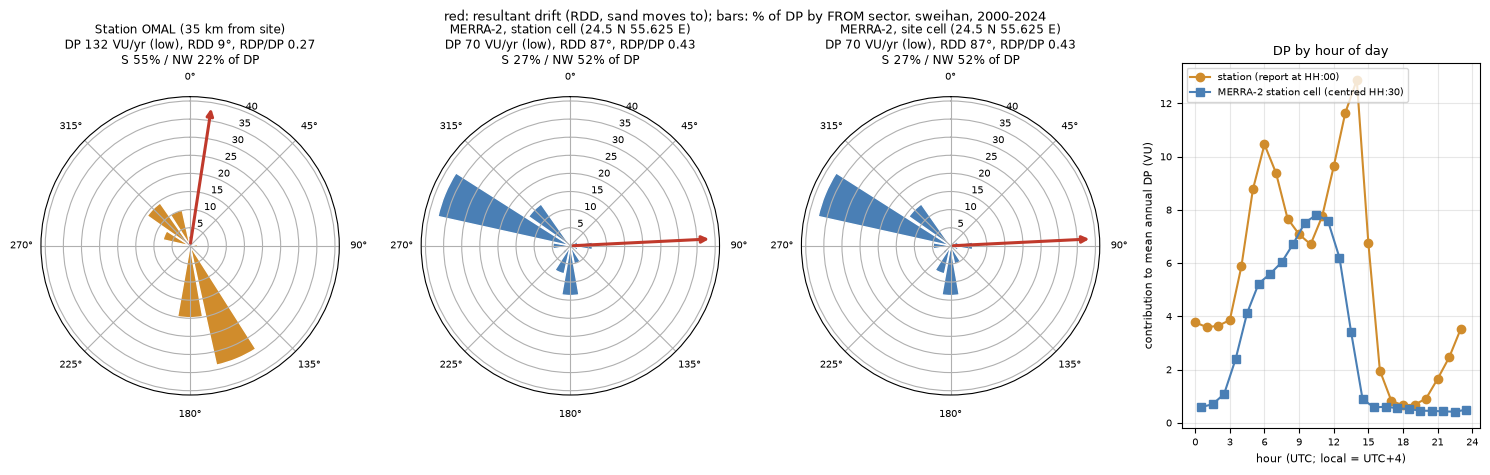

In [15]:
# WHAT THIS DOES: draws the station and MERRA-2 sand roses side by side (bars point to the FROM direction, length =
# share of DP), each with its resultant drift arrow (toward RDD), the measured dune heading where notebook 02 has one,
# and the DP contribution by hour of day for the station and MERRA-2.
if HAS_STATION:
    fig = plt.figure(figsize=(15, 4.8))
    panels = [(f"Station {STN[PRIMARY]['icao'] or PRIMARY} ({STN[PRIMARY]['distance_to_site_km']:.0f} km from site)", s_st),
              (f"MERRA-2, station cell ({cc['lat_c']} N {cc['lon_c']} E)", s_mc),
              (f"MERRA-2, site cell ({SITE_CELL['lat_c']} N {SITE_CELL['lon_c']} E)", s_ms)]
    rmax = max(100 * p["rose_from"].max() / p["rose_from"].sum() for _, p in panels) * 1.1
    for k, (title, p) in enumerate(panels):
        ax = fig.add_subplot(1, 4, k + 1, projection="polar")
        ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
        share = 100 * p["rose_from"] / p["rose_from"].sum()
        ax.bar(np.radians(np.arange(16) * 22.5), share, width=np.radians(20), color="#4a7fb5" if k else "#d08c2c",
               edgecolor="white", linewidth=1)
        ax.annotate("", xy=(np.radians(p["RDD_deg"]), rmax * 0.95), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color="#c0392b", lw=2.2))
        if DUNE:
            ax.annotate("", xy=(np.radians(DUNE["field_median_heading_deg"]), rmax * 0.95), xytext=(0, 0),
                        arrowprops=dict(arrowstyle="-|>", color="#1e8449", lw=2.2, ls="--"))
        ax.set_ylim(0, rmax); ax.tick_params(labelsize=7)
        ax.set_title(f"{title}\nDP {p['DP']:.0f} VU/yr ({p['dp_class']}), RDD {p['RDD_deg']:.0f}°, RDP/DP {p['RDP_DP']:.2f}\n"
                     f"S {100 * p['S (157.5-202.5)']:.0f}% / NW {100 * p['NW (292.5-315)']:.0f}% of DP", fontsize=8.5)
    ax = fig.add_subplot(1, 4, 4)
    ax.plot(BY_HOUR.index, BY_HOUR[("station", "DP_contrib")], "o-", color="#d08c2c", label="station (report at HH:00)")
    ax.plot(BY_HOUR.index + 0.5, BY_HOUR[("merra2", "DP_contrib")], "s-", color="#4a7fb5", label="MERRA-2 station cell (centred HH:30)")
    ax.set_xlabel("hour (UTC; local = UTC+4)", fontsize=8); ax.set_ylabel("contribution to mean annual DP (VU)", fontsize=8)
    ax.set_xticks(range(0, 25, 3)); ax.tick_params(labelsize=7); ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="upper left")
    ax.set_title("DP by hour of day", fontsize=9)
    sub = (f"red: resultant drift (RDD, sand moves to)" + (f"; green dashed: measured dune heading {DUNE['field_median_heading_deg']:.0f}° (notebook 02)" if DUNE else "")
           + f"; bars: % of DP by FROM sector. {SID}, 2000-2024")
    fig.suptitle(sub, fontsize=9)
    fig.tight_layout(); fig.savefig(OUT / "station_vs_merra2_sand_rose.png", dpi=110); plt.show()

In [16]:
# WHAT THIS DOES: writes pipeline/outputs/<site>/station_wind_check.json: the stations (identity, position, distance,
# completeness, decoding counts), the station vs MERRA-2 comparison, roses, month/hour breakdowns, paired statistics,
# sensitivity, secondary stations, and the direct answers computed from them.
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, np.ndarray): return [clean(v) for v in o.tolist()]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else round(float(o), 4)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (pd.Timestamp, dt.datetime)): return o.isoformat()
    return o

result = {"site": SID, "generated_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
          "site_centre": {"lat": LAT_C, "lon": LON_C}, "period": f"{YEARS[0]}-{YEARS[-1]}",
          "source": "NOAA NCEI Integrated Surface Database (Global Hourly), via the NOAA Open Data bucket",
          "screen": {"radius_km": SCREEN_RADIUS, "rule": "usable: >= 10 years with >= 2000 hours carrying a valid wind report; primary: nearest usable with >= 7000 such hours in >= 10 years",
                     "candidates": scr.to_dict("records") if len(scr) else []},
          "primary_station": PRIMARY, "secondary_stations": SECONDARY, "has_usable_station": HAS_STATION}
if HAS_STATION:
    def pack(s):
        return {**{k: s[k] for k in ROW_KEYS}, "rose_from_vu": s["rose_from"]}
    dh = DUNE["field_median_heading_deg"] if DUNE else None
    answers = {"station_RDD_deg": s_st["RDD_deg"], "merra2_station_cell_RDD_deg": s_mc["RDD_deg"], "merra2_site_cell_RDD_deg": s_ms["RDD_deg"],
               "station_S_over_NW": s_st["S_over_NW"], "merra2_station_cell_S_over_NW": s_mc["S_over_NW"], "merra2_site_cell_S_over_NW": s_ms["S_over_NW"],
               "DP_ratio_station_over_merra2_station_cell": s_st["DP"] / s_mc["DP"], "DP_ratio_station_over_merra2_site_cell": s_st["DP"] / s_ms["DP"],
               "dp_class_station": s_st["dp_class"], "dp_class_merra2_site_cell": s_ms["dp_class"],
               "mode_DP_ratio_station_over_merra2_station_cell": {k: v["DP_ratio_station_over_merra2"] for k, v in PAIRED["by_mode"].items()},
               "mode_speed_ratio_station_over_merra2_when_both_from_mode": {k: v["speed_ratio_station_over_merra2_when_both"] for k, v in PAIRED["by_mode"].items()},
               "station_RDD_with_speeds_scaled_to_merra2_mean_deg": float(SENS.loc[SENS.case.str.startswith("MERRA-2 threshold"), "RDD_deg"].iloc[0])}
    if dh is not None:
        answers.update({"dune_field_median_heading_deg": dh,
                        "angle_station_RDD_to_dune_deg": float(wind.angle_diff(s_st["RDD_deg"], dh)),
                        "angle_merra2_site_RDD_to_dune_deg": float(wind.angle_diff(s_ms["RDD_deg"], dh)),
                        "angle_merra2_station_cell_RDD_to_dune_deg": float(wind.angle_diff(s_mc["RDD_deg"], dh))})
    result.update({
        "stations": STN, "decoding": REPORTS,
        "completeness_pct_by_year": {k: v.to_dict() for k, v in COMPLETENESS.items()},
        "completeness_primary_pct_by_hour_utc": (100 * H.groupby(H.index.hour).size() / len(pd.date_range(f"{YEARS[0]}-01-01", f"{YEARS[-1]}-12-31", freq="D"))).to_dict(),
        "handling": {"one_report_per_utc_hour": "nearest valid report within +/-10 min of HH:00; METAR > SY-MT > SYNOP; SPECI excluded",
                     "speeds": "whole knots recovered from ISD m/s (round(ms / 0.514444))", "calms": "valid hours, zero drift",
                     "variable_no_direction": "valid hours; dropped only if above 12 kt", "qc": "speed or direction quality code 2, 3, 6, 7 rejected",
                     "time_weighting": "t = 100 / N observed hours per year (dunesight.wind); gap-weighted variant in sensitivity",
                     "rose": "each report spread over its 10-degree direction bin (stations.split_directions)",
                     "averaging_time": "METAR/SYNOP 10-min means (WMO) vs MERRA-2 hourly means; not corrected, proxy in sensitivity",
                     "anemometer_height": "not given by ISD or OSCAR for these stations; WMO standard is 10 m; +/-5 % speed row in sensitivity"},
        "comparison": [{**{k: (r[k] if k in r else None) for k in ("period", "series")}, **pack(SUMS[(r["period"], r["series"])])} for _, r in COMPARE.iterrows()],
        "by_month": json.loads(flat(BY_MONTH).to_json(orient="index")), "by_hour_utc": json.loads(flat(BY_HOUR).to_json(orient="index")),
        "mode_share_by_hour_utc_pct": json.loads(flat(MODE_HOUR).to_json(orient="index")),
        "paired_hourly": PAIRED, "sensitivity": SENS.to_dict("records"),
        "yearly": json.loads(YEARLY.to_json(orient="index")),
        "secondary": SECOND.to_dict("records") if isinstance(SECOND, pd.DataFrame) else [],
        "dune_motion_from_02": DUNE, "answers": answers})
(OUT / "station_wind_check.json").write_text(json.dumps(clean(result), indent=1))
print("wrote", (OUT / "station_wind_check.json").relative_to(config.ROOT))
if HAS_STATION:
    print(json.dumps(clean(result["answers"]), indent=1))

wrote pipeline/outputs/sweihan/station_wind_check.json
{
 "station_RDD_deg": 8.7315,
 "merra2_station_cell_RDD_deg": 87.1915,
 "merra2_site_cell_RDD_deg": 87.1915,
 "station_S_over_NW": 2.4895,
 "merra2_station_cell_S_over_NW": 0.5188,
 "merra2_site_cell_S_over_NW": 0.5188,
 "DP_ratio_station_over_merra2_station_cell": 1.8794,
 "DP_ratio_station_over_merra2_site_cell": 1.8794,
 "dp_class_station": "low",
 "dp_class_merra2_site_cell": "low",
 "mode_DP_ratio_station_over_merra2_station_cell": {
  "S (157.5-202.5)": 3.8637,
  "NW (292.5-315)": 0.8051
 },
 "mode_speed_ratio_station_over_merra2_when_both_from_mode": {
  "S (157.5-202.5)": 1.3548,
  "NW (292.5-315)": 0.9953
 },
 "station_RDD_with_speeds_scaled_to_merra2_mean_deg": 2.8071
}


In [17]:
# WHAT THIS DOES: shows the written interpretation of this check for the site (pipeline/site_notes/<site>/01b_station_wind.md).
_f = NOTES / "01b_station_wind.md"
display(Markdown(_f.read_text()) if _f.exists() else Markdown(f"**No written note yet for {SID}** ({_f.relative_to(config.ROOT)})."))

## What the station winds say (written from the 2026-11-14 run; check the numbers above)

**Stations.** The nearest hourly station is Al Ain International (OMAL, WMO 41218), **35 km SE** of the box centre at 265 m. Its MERRA-2 cell (24.5 N 55.625 E) is also the Sweihan site cell, so the station-cell and site-cell MERRA-2 rows are the same series. Two secondary stations: Al Maktoum International (OMDW, ISD 411945-99999, not a WMO number), **50 km NNW** at 19 m, hourly from mid-2010, about 15-20 km from the Gulf coast; and Buraimi (WMO 41244, synoptic), 52 km ESE.

**Result.** The primary-station numbers are the Seih Al Hama ones (same station): DP 132 VU/yr (1.9 × MERRA-2's 70), RDD ≈ 9° against MERRA-2's 87°, S/NW mode ratio 2.5 against 0.5. But the two stations that bracket Sweihan **disagree with each other**: Al Maktoum, at the synoptic hours shared with Al Ain in 2010-2024, has DP 146, **RDD 99°** and S/NW 0.64, i.e. the MERRA-2 direction (MERRA-2 at its own cell: RDD 99°) with about twice the drift; Al Ain at the same hours has RDD 2°. Buraimi, further inland, agrees with Al Ain (RDD 341°, S/NW 2.3).

**Reading.** The strong southerly mode looks like a feature of the inland Al Ain-Buraimi plain near the mountains; the coastal station does not have it. Sweihan lies between the two, 35 km from Al Ain and 50 km from the coast, so **the station data do not tell us which regime holds at Sweihan**. Both stations do agree that MERRA-2's DP is about half the observed value (DP still low, < 200 VU, in both). There is no dune-tracking result for Sweihan yet, so no heading to compare.
